# Aprendo +

---
---

# Caso Práctico

---
---

# Setup

In [1]:
import duckdb
import pyprojroot
import pandas as pd

In [2]:
# 1. Configuración habitual de pandas
pd.options.display.max_columns = None
pd.options.display.max_colwidth = None

from IPython.display import HTML, display
# 2. Inyectar CSS para prohibir los saltos de línea en todas las tablas del notebook
display(HTML("<style>.dataframe td { white-space: nowrap !important; }</style>"))

In [3]:
db_path = pyprojroot.here() / "data" / "raw" / "aprendo_caso.sqlite"

In [4]:
conn = duckdb.connect()

In [5]:
conn.execute(f"ATTACH '{db_path}'AS db (TYPE sqlite)")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

# Tasa de Participación

**Métrica principal.** Tasa de participación semanal = familias distintas con al menos una respuesta con evidencia (foto, audio o video) en las actividades de la semana ÷ familias registradas hasta el fin de esa semana. Una persona cuenta una sola vez aunque tenga más de un registro.

$$\text{Tasa de participación semanal} = \frac{\text{familias distintas con al menos una respuesta con evidencia}}{\text{familias registradas hasta el fin de esa semana}}$$

In [ ]:
statement = """
-- Se indica: Una persona cuenta una sola vez aunque tenga más de un registro.
-- Se considera: utilizar la primera `fecha_alta` de cada `telefono_hash` para deduplicar registros de familias.
CREATE OR REPLACE VIEW v_familias AS
SELECT
    p.telefono_hash,
    FIRST(it.ugel) AS ugel,
    FIRST(it.institucion_id) AS institucion_id,
    FIRST(it.zona) AS zona,
    FIRST(p.grupo_id) AS grupo_id,
    MIN(CAST(p.fecha_alta AS DATE)) AS fecha_alta,
    DATE_TRUNC('week', MIN(p.fecha_alta)::DATE) + INTERVAL 6 DAY AS fin_de_semana
FROM db.participantes p
JOIN db.grupos g
ON g.grupo_id = p.grupo_id
JOIN db.instituciones it
ON it.institucion_id = g.institucion_id
WHERE p.rol = 'familia'
GROUP BY p.telefono_hash; -- 1023 registros = 1101 (originales) - 48 (docentes) -  30 (telefonos duplicados)

-- Interacciones válidas en hora Lima, con el tipo normalizado y la semana de su actividad.
CREATE OR REPLACE VIEW v_evidencias AS
SELECT
    f.telefono_hash,
    f.ugel,
    f.institucion_id,
    f.zona,
    f.grupo_id,
    i.actividad_id,
    CAST(a.fecha_envio_utc AS TIMESTAMP) - INTERVAL 5 HOUR AS fecha_envio,
    a.semana,
    CAST(i.fecha_hora_utc AS TIMESTAMP) - INTERVAL 5 HOUR AS fecha_evidencia,
    LOWER(TRIM(i.tipo)) AS tipo,
    DATE_TRUNC('week', (i.fecha_hora_utc::TIMESTAMP - INTERVAL 5 HOUR)::DATE) + INTERVAL 6 DAY AS fin_de_semana,
FROM db.interacciones i
JOIN db.actividades a
ON a.actividad_id = i.actividad_id
JOIN db.participantes p
ON p.participante_id = i.participante_id AND p.rol = 'familia'
JOIN v_familias f
ON f.telefono_hash = p.telefono_hash -- 18  filas afectadas (cambié la consulta, revisar)
WHERE
    i.fecha_hora_utc::TIMESTAMP - INTERVAL 5 HOUR > a.fecha_envio_utc::TIMESTAMP - INTERVAL 5 HOUR -- 50 filas afectadas
    AND LOWER(TRIM(i.tipo)) in ('foto', 'imagen', 'audio', 'video'); -- 3275 filas

CREATE OR REPLACE VIEW v_evidencias_semanales AS
WITH evidencias_enviadas AS (
    SELECT
        semana,
        fin_de_semana,
        ugel,
        institucion_id,
        zona,
        grupo_id,
        COUNT(DISTINCT telefono_hash) as evidencias,
    FROM v_evidencias
    GROUP BY semana, fin_de_semana, ugel, institucion_id, zona, grupo_id
    ORDER BY semana, fin_de_semana, ugel, grupo_id
), -- 287 registros, deberían ser 288 = 48 grupos x 6 semanas

grilla AS (
    SELECT
        v_e_s.semana,
        v_e_s.fin_de_semana,
        u_g.ugel,
        u_g.institucion_id,
        u_g.zona,
        u_g.grupo_id,
    FROM (
        SELECT
            semana,
            FIRST(fin_de_semana) AS fin_de_semana
        FROM evidencias_enviadas
        GROUP BY semana
    ) v_e_s
    CROSS JOIN (
        SELECT
            it.ugel,
            it.institucion_id,
            it.zona,
            g.grupo_id
        FROM db.grupos g
        JOIN db.instituciones it
        ON g.institucion_id = it.institucion_id
    ) u_g
) -- 288 registros, se usa para imputar los grupo x semana sin evidencias enviadas

SELECT
    COALESCE(e.semana, g.semana) AS semana,
    COALESCE(e.fin_de_semana, g.fin_de_semana) AS fin_de_semana,
    COALESCE(e.ugel, g.ugel) AS ugel,
    COALESCE(e.institucion_id, g.institucion_id) AS institucion_id,
    COALESCE(e.zona, g.zona) AS zona,
    COALESCE(e.grupo_id, g.grupo_id) AS grupo_id,
    COALESCE(e.evidencias, 0) AS evidencias,
FROM evidencias_enviadas e
FULL JOIN grilla g
ON e.semana = g.semana AND e.ugel = g.ugel AND e.grupo_id = g.grupo_id
ORDER BY semana, ugel, grupo_id; -- 288 registros completos sin nulos

CREATE OR REPLACE VIEW v_grupo_semana AS
WITH familias_agrupadas AS (
    SELECT
        fin_de_semana,
        ugel,
        institucion_id,
        zona,
        grupo_id,
        COUNT(*) as registradas,
    FROM v_familias
    GROUP BY fin_de_semana, ugel, institucion_id, zona, grupo_id
    ORDER BY fin_de_semana, ugel, grupo_id
),

registros_semanales AS (
    SELECT
        fin_de_semana,
        ugel,
        institucion_id,
        zona,
        grupo_id,
        registradas,
        SUM(registradas) OVER (
            PARTITION BY ugel, grupo_id
            ORDER BY fin_de_semana
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) AS registradas_acumuladas
    FROM familias_agrupadas
    ORDER BY fin_de_semana, ugel, grupo_id
),

evidencias_registros AS (
    SELECT
        e_s.semana,
        COALESCE(e_s.fin_de_semana, r_s.fin_de_semana) AS fin_de_semana,
        COALESCE(e_s.ugel, r_s.ugel) AS ugel,
        COALESCE(e_s.institucion_id, r_s.institucion_id) AS institucion_id,
        COALESCE(e_s.zona, r_s.zona) AS zona,
        COALESCE(e_s.grupo_id, r_s.grupo_id) AS grupo_id,
        e_s.evidencias,
        r_s.registradas_acumuladas
    FROM v_evidencias_semanales e_s
    FULL JOIN registros_semanales r_s
    ON e_s.ugel = r_s.ugel AND e_s.grupo_id = r_s.grupo_id AND e_s.fin_de_semana = r_s.fin_de_semana
    ORDER BY fin_de_semana, ugel, grupo_id
),

imputado AS (
    SELECT
        * EXCLUDE registradas_acumuladas,
        LAST_VALUE(registradas_acumuladas IGNORE NULLS) OVER (
            PARTITION BY ugel, grupo_id
            ORDER BY fin_de_semana
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        )::INT AS registradas
    FROM evidencias_registros
)

SELECT
    * 
FROM imputado
WHERE semana IS NOT NULL
ORDER BY fin_de_semana, ugel, grupo_id;
"""

conn.execute(statement);

## 1. La tasa de participación semanal por UGEL y en total, para las 6 semanas.

In [35]:
t1 = conn.execute("""SELECT semana,
    ROUND(100.0 * SUM(evidencias) FILTER (WHERE ugel = 'UGEL A') / SUM(registradas) FILTER (WHERE ugel = 'UGEL A'), 1) AS "UGEL A",
    ROUND(100.0 * SUM(evidencias) FILTER (WHERE ugel = 'UGEL B') / SUM(registradas) FILTER (WHERE ugel = 'UGEL B'), 1) AS "UGEL B",
    ROUND(100.0 * SUM(evidencias) FILTER (WHERE ugel = 'UGEL C') / SUM(registradas) FILTER (WHERE ugel = 'UGEL C'), 1) AS "UGEL C",
    ROUND(100.0 * SUM(evidencias) / SUM(registradas), 1) AS "Total"
FROM v_grupo_semana
GROUP BY semana
ORDER BY semana;
"""
).df()

In [36]:
t1

,semana,UGEL A,UGEL B,UGEL C,Total
0,1,38.1,37.2,31.0,35.4
1,2,43.3,35.7,31.7,36.8
2,3,42.4,21.8,36.0,33.4
3,4,48.1,41.0,36.6,41.8
4,5,42.1,39.2,28.5,36.6
5,6,40.7,33.9,24.2,32.8


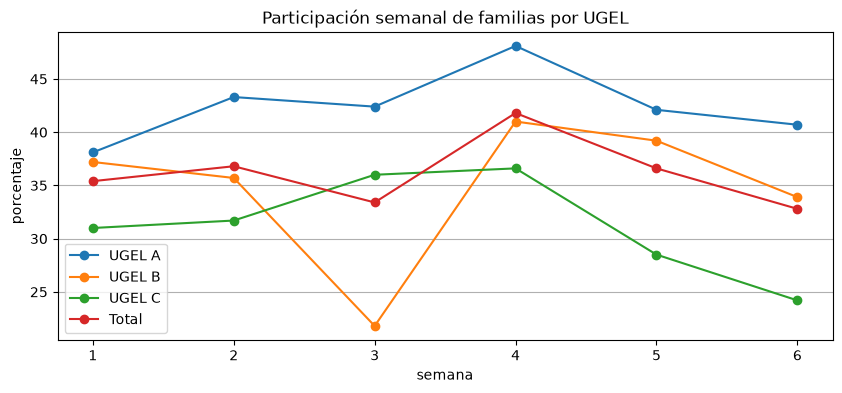

In [37]:
t1.set_index('semana').plot(kind='line', marker='o',
                            title='Participación semanal de familias por UGEL',
                            figsize=(10,4), ylabel='porcentaje').grid(axis='y');

Observaciones:
- UGEL B, semana 3: sin ninguna interacción de las actividades `ACT013` y `ACT014`.
- UGEL C, semana 6: sin ninguna interacción del grupo `G-C06-4`.

---

## 2. Los 5 grupos con mayor caída de participación entre el promedio de las semanas 1 a 4 y el promedio de las semanas 5 y 6.

In [43]:
t2 = conn.execute("""
WITH tasa_grupo AS (
    SELECT grupo_id, ugel, institucion_id, zona, semana, 100.0 * evidencias / registradas AS tasa
    FROM v_grupo_semana
)
           
SELECT
    grupo_id, ugel, institucion_id, zona,
    ROUND(AVG(tasa) FILTER (WHERE semana BETWEEN 1 AND 4), 1) AS prom_sem_1_4,
    ROUND(AVG(tasa) FILTER (WHERE semana IN (5, 6)), 1) AS prom_sem_5_6,
    ROUND(AVG(tasa) FILTER (WHERE semana BETWEEN 1 AND 4) - AVG(tasa) FILTER (WHERE semana IN (5, 6)), 1) AS caida_pp
FROM tasa_grupo
GROUP BY grupo_id, ugel, institucion_id, zona
ORDER BY AVG(tasa) FILTER (WHERE semana BETWEEN 1 AND 4) - AVG(tasa) FILTER (WHERE semana IN (5, 6)) DESC, grupo_id
LIMIT 10;
""").df()

t2

,grupo_id,ugel,institucion_id,zona,prom_sem_1_4,prom_sem_5_6,caida_pp
0,G-C06-5,UGEL C,IE-C06,rural,44.2,9.6,34.6
1,G-C07-5,UGEL C,IE-C07,rural,38.3,5.9,32.4
2,G-C07-4,UGEL C,IE-C07,rural,37.1,8.8,28.3
3,G-C06-4,UGEL C,IE-C06,rural,35.5,8.3,27.1
4,G-C05-5,UGEL C,IE-C05,rural,38.3,12.5,25.8
5,G-B07-4,UGEL B,IE-B07,urbana,43.5,28.3,15.2
6,G-A04-5,UGEL A,IE-A04,rural,54.8,40.5,14.3
7,G-C08-4,UGEL C,IE-C08,urbana,42.4,31.0,11.5
8,G-A03-4,UGEL A,IE-A03,rural,39.1,28.1,10.9
9,G-A03-5,UGEL A,IE-A03,rural,27.3,16.7,10.7


Observaciones:

- Los cinco grupos con mayor caída pertenecen a tres instituciones educativas `IE-C05`, `IE-C06` e `IE-C07` de zona `rural` de la `UGEL C`. 
- El siguiente grupo con mayor caída es `G-B07-4` y dista de los 5 primeros grupos en más de 10 pp. 

## 3. Cuántas famlilias participaron con evidencia en al menos 2 semanas distintas, de las semanas 1 a 4 y no participaron con evidencia en las semanas 5 y 6, y en qué grupos se concentran.

In [73]:
t3_a = conn.execute("""
CREATE OR REPLACE VIEW v_abandonan AS
SELECT f.telefono_hash, f.grupo_id, f.ugel, f.zona,
FROM v_familias f
WHERE (SELECT COUNT(DISTINCT e.semana) FROM v_evidencias e
       WHERE e.telefono_hash = f.telefono_hash AND e.semana BETWEEN 1 AND 4) >= 2
  AND NOT EXISTS (SELECT 1 FROM v_evidencias e
                  WHERE e.telefono_hash = f.telefono_hash AND e.semana IN (5, 6));

-- Total
SELECT COUNT(*) AS familias_que_dejan_de_participar FROM v_abandonan;
""").df()

t3_a

,familias_que_dejan_de_participar
0,144


In [75]:
t3_b = conn.execute("""
SELECT a.grupo_id, a.ugel, a.zona, COUNT(*) AS familias,
       (SELECT COUNT(*) FROM v_familias f WHERE f.grupo_id = a.grupo_id) AS familias_grupo,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM v_familias f WHERE f.grupo_id = a.grupo_id), 1) AS pct_del_grupo
FROM v_abandonan a
GROUP BY a.grupo_id, a.ugel, a.zona,
ORDER BY familias DESC, a.grupo_id;
""").df()

t3_b

,grupo_id,ugel,zona,familias,familias_grupo,pct_del_grupo
0,G-C05-5,UGEL C,rural,10,24,41.7
1,G-C06-5,UGEL C,rural,10,26,38.5
2,G-A04-5,UGEL A,rural,5,21,23.8
3,G-B02-5,UGEL B,rural,5,17,29.4
4,G-C05-4,UGEL C,rural,5,25,20.0
5,G-C06-4,UGEL C,rural,5,18,27.8
6,G-C07-4,UGEL C,rural,5,17,29.4
7,G-C07-5,UGEL C,rural,5,17,29.4
8,G-A01-5,UGEL A,urbana,4,20,20.0
9,G-A03-4,UGEL A,rural,4,16,25.0


In [78]:
t3_b.head(10)

,grupo_id,ugel,zona,familias,familias_grupo,pct_del_grupo
0,G-C05-5,UGEL C,rural,10,24,41.7
1,G-C06-5,UGEL C,rural,10,26,38.5
2,G-A04-5,UGEL A,rural,5,21,23.8
3,G-B02-5,UGEL B,rural,5,17,29.4
4,G-C05-4,UGEL C,rural,5,25,20.0
5,G-C06-4,UGEL C,rural,5,18,27.8
6,G-C07-4,UGEL C,rural,5,17,29.4
7,G-C07-5,UGEL C,rural,5,17,29.4
8,G-A01-5,UGEL A,urbana,4,20,20.0
9,G-A03-4,UGEL A,rural,4,16,25.0


Observaciones:
- En el top 10 de grupos de familias que dejan de participar, el 90% son de zona rural.

## 4. Consultas de control de calidad que cuantifiquen los problemas que encuentres en los datos.

### `telefono_hash` repetidos

In [105]:
detalle_de_repetidos = conn.execute("""
SELECT p.*
FROM db.participantes p
JOIN (SELECT telefono_hash, COUNT(*) AS n FROM db.participantes GROUP BY telefono_hash HAVING COUNT(*) > 1) r
ON p.telefono_hash = r.telefono_hash
ORDER BY telefono_hash, fecha_alta
""").df()

detalle_de_repetidos

,participante_id,grupo_id,rol,telefono_hash,fecha_alta
0,P00026,G-A01-4,familia,0bc620d799,2026-08-09
1,P01097,G-A01-4,familia,0bc620d799,2026-08-24
2,P00313,G-A08-4,familia,0e79861f25,2026-08-06
3,P01095,G-A08-4,familia,0e79861f25,2026-09-13
4,P01071,G-C08-5,familia,16055f0014,2026-08-03
5,P01078,G-C08-5,familia,16055f0014,2026-09-06
6,P00341,G-A08-5,familia,2176fffe4d,2026-08-04
7,P01087,G-A08-5,familia,2176fffe4d,2026-08-24
8,P00270,G-A07-4,familia,2380d9bde1,2026-08-12
9,P01100,G-A07-4,familia,2380d9bde1,2026-08-28


In [107]:
cantidad_de_repetidos = conn.execute("""
SELECT
    COUNT(*) AS telefonos_repetidos,
    SUM(n) - COUNT(*) AS filas_sobrantes
FROM (SELECT
        telefono_hash,
        COUNT(*) AS n
      FROM db.participantes
      GROUP BY telefono_hash
      HAVING COUNT(*) > 1);
""").df()

cantidad_de_repetidos

,telefonos_repetidos,filas_sobrantes
0,30,30.0


Observaciones:
- Hay 30 `telefono_hash` que aparecen para como máximo dos `participante_id`, cada uno con su propia `fecha_alta`.
- Cada repetición ocurre dentro del mismo `grupo_id`.

### Familias que participan sin registrarse

In [119]:
participan_sin_registro = conn.execute("""
SELECT COUNT(*) AS interacciones_totales,
       COUNT(DISTINCT participante_id) AS familias_no_registrados,
       COUNT(*) FILTER (WHERE LOWER(TRIM(tipo)) IN ('foto','imagen','audio','video')) AS interacciones_con_evidencia
FROM db.interacciones
WHERE participante_id NOT IN (SELECT participante_id FROM db.participantes);
""").df()

participan_sin_registro

,interacciones_totales,familias_no_registrados,interacciones_con_evidencia
0,40,40,18


Observaciones:
- En la tabla `interacciones` hay `40` interacciones, `18 con evidencia`, de famlias que no están registradas en la tabla `participantes`, es decir no tienen `participante_id`, `ugel`, ni `grupo_id` asociados.

### Interacciones duplicadas

In [122]:
iteracciones_duplicadas = conn.execute("""
SELECT COUNT(*) AS interacciones_duplicadas
FROM (SELECT ROW_NUMBER() OVER (PARTITION BY participante_id, actividad_id, fecha_hora_utc, tipo
                                ORDER BY interaccion_id) AS rn
      FROM db.interacciones)
WHERE rn > 1;
""").df()

iteracciones_duplicadas

,interacciones_duplicadas
0,137


Observaciones:
- Hay `137` filas duplicadas en la tabla `interacciones`.

### Tipos de interacciones

In [125]:
tipos = conn.execute("""
SELECT tipo, LENGTH(tipo) AS largo, COUNT(*) AS filas,
       LOWER(TRIM(tipo)) AS normalizado
FROM db.interacciones
GROUP BY tipo
ORDER BY filas DESC;
""").df()

tipos

,tipo,largo,filas,normalizado
0,texto,5,1912,texto
1,foto,4,1481,foto
2,reaccion,8,1068,reaccion
3,audio,5,875,audio
4,reenvio,7,733,reenvio
5,video,5,617,video
6,Foto,4,87,foto
7,Audio,5,79,audio
8,imagen,6,78,imagen
9,FOTO,5,66,foto


Observaciones:
- Los `tipos de interacciones` no están normalizados, el caso más heterogéneo es el respectivo a `'foto'`, que originalmente se ha registrado como `'foto'`, `'Foto'` y `'FOTO '` utilizando mayúsculas y espacios de forma desordenada.

### Interacciones tempranas

In [128]:
interacciones_tempranas = conn.execute("""
SELECT
    f.telefono_hash,
    f.ugel,
    f.institucion_id,
    f.zona,
    f.grupo_id,
    i.actividad_id,
    CAST(a.fecha_envio_utc AS TIMESTAMP) - INTERVAL 5 HOUR AS fecha_envio,
    a.semana,
    CAST(i.fecha_hora_utc AS TIMESTAMP) - INTERVAL 5 HOUR AS fecha_evidencia,
    LOWER(TRIM(i.tipo)) AS tipo,
    DATE_TRUNC('week', (i.fecha_hora_utc::TIMESTAMP - INTERVAL 5 HOUR)::DATE) + INTERVAL 6 DAY AS fin_de_semana,
FROM db.interacciones i
JOIN db.actividades a
ON a.actividad_id = i.actividad_id
JOIN db.participantes p
ON p.participante_id = i.participante_id AND p.rol = 'familia'
JOIN v_familias f
ON f.telefono_hash = p.telefono_hash -- 18  filas afectadas (cambié la consulta, revisar)
WHERE
    i.fecha_hora_utc::TIMESTAMP - INTERVAL 5 HOUR < a.fecha_envio_utc::TIMESTAMP - INTERVAL 5 HOUR -- 50 filas afectadas
    AND LOWER(TRIM(i.tipo)) in ('foto', 'imagen', 'audio', 'video');
""").df()

interacciones_tempranas

,telefono_hash,ugel,institucion_id,zona,grupo_id,actividad_id,fecha_envio,semana,fecha_evidencia,tipo,fin_de_semana
0,b2e16fff04,UGEL B,IE-B01,rural,G-B01-5,ACT001,2026-08-17 18:00:00,1,2026-08-17 07:14:53,audio,2026-08-23
1,b1015c296f,UGEL A,IE-A07,urbana,G-A07-5,ACT003,2026-08-19 18:00:00,1,2026-08-19 04:51:55,audio,2026-08-23
2,a5f19d0cb8,UGEL C,IE-C05,rural,G-C05-4,ACT003,2026-08-19 18:00:00,1,2026-08-19 05:24:32,audio,2026-08-23
3,fed54cb4ff,UGEL A,IE-A07,urbana,G-A07-5,ACT003,2026-08-19 18:00:00,1,2026-08-19 14:53:39,foto,2026-08-23
4,463e27834e,UGEL A,IE-A08,rural,G-A08-5,ACT004,2026-08-20 18:00:00,1,2026-08-20 13:24:49,foto,2026-08-23
5,3565103f3c,UGEL B,IE-B01,rural,G-B01-4,ACT005,2026-08-21 18:00:00,1,2026-08-21 14:34:26,foto,2026-08-23
6,c308f7838a,UGEL B,IE-B04,rural,G-B04-4,ACT007,2026-08-25 18:00:00,2,2026-08-25 00:48:51,video,2026-08-30
7,8f17b90dda,UGEL A,IE-A05,rural,G-A05-4,ACT007,2026-08-25 18:00:00,2,2026-08-25 06:18:58,audio,2026-08-30
8,982b6d55da,UGEL B,IE-B04,rural,G-B04-4,ACT008,2026-08-26 18:00:00,2,2026-08-25 18:38:12,foto,2026-08-30
9,f340080435,UGEL A,IE-A05,rural,G-A05-4,ACT009,2026-08-27 18:00:00,2,2026-08-26 15:25:41,foto,2026-08-30


Observaciones:
- Hay `31 interacciones con evidencia` registradas antes de que el docente envíe la actividad.

### Grupos - Actividad sin interacciones

In [136]:
huecos_de_datos = conn.execute("""
WITH ga AS (
    SELECT
        g.grupo_id,
        i.ugel,
        a.actividad_id,
        a.semana,
        a.fecha_envio_utc
    FROM db.grupos g
    JOIN db.instituciones i USING (institucion_id)
    CROSS JOIN db.actividades a
),

n AS (
    SELECT
        p.grupo_id,
        x.actividad_id,
        COUNT(*) AS filas
    FROM db.interacciones x
    JOIN db.participantes p USING (participante_id)
    GROUP BY ALL
)

SELECT
    ga.semana,
    ga.actividad_id,
    ga.ugel,
    COUNT(*) AS grupos_sin_datos
FROM ga LEFT JOIN n USING (grupo_id, actividad_id)
WHERE n.filas IS NULL
GROUP BY ALL
ORDER BY grupos_sin_datos DESC, ga.actividad_id, ga.ugel;
""").df()

huecos_de_datos

,semana,actividad_id,ugel,grupos_sin_datos
0,3,ACT013,UGEL B,16
1,3,ACT014,UGEL B,16
2,6,ACT026,UGEL C,6
3,6,ACT030,UGEL C,5
4,6,ACT027,UGEL C,4
5,6,ACT029,UGEL C,3
6,1,ACT005,UGEL C,2
7,2,ACT007,UGEL C,2
8,5,ACT023,UGEL C,2
9,5,ACT025,UGEL A,2


Observaciones:
- Ningún grupo de la `UGEL B` registró interacciones en la `semana 3` para las actividades `ACT013` y `ACT014`, eso explica el outlier en la métrica.
- Varios grupos de la `UGEL C` dejaron de participar en las actividades `ACT026`, `ACT027`, `ACT029` y `ACT030` durante la `semana 6`, esto también se refleja en la métrica de participación.